# Assignment 6 — Multiclass land use/cover mapping with U-Net


### 5. Homework: multiclass land use/cover mapping with U-Net

**Objective:** Adapt the building footprint tutorial to predict one land use/cover category for every valid pixel in NAIP imagery. Your result must contain at least **three meaningful categories**, including buildings, rather than a binary building mask. Use the categories available in the supplied reference raster (for example, vegetation, buildings, water, and other surfaces if supported by its legend). Do not invent class names from pixel values: verify the source legend and document any regrouping. Imagery primarily reveals land cover; discuss limitations when interpreting functional land use.

#### Assignment

1. **Inspect and prepare the labels.** List the raw raster codes and their meanings, identify no-data values, and create a table mapping each selected source code to a contiguous training ID (`0, ..., C-1`). Report pixel counts per class. Keep image/mask grids aligned, including CRS, extent, and pixel size. Use nearest-neighbor resampling for labels. Explain how you handle excluded categories and no-data pixels.
2. **Create a spatial split.** Reserve separate geographic areas for training, validation, and testing before augmentation. Keep neighboring or overlapping tiles out of different splits to reduce spatial leakage. Show the split on a map and report tile counts. Use validation data to select settings; evaluate on the held-out test area only after those choices are fixed.
3. **Adapt and train U-Net.** Replace the binary mask conversion in every label-loading path with your multiclass mapping. Set `out_channels=C`, train with `CrossEntropyLoss`, and plot training and validation loss. Record the class mapping, input bands, normalization, split, random seed, learning rate, batch size, and epochs. Save the selected model checkpoint. If classes are imbalanced, try a documented strategy such as training-set class weights and compare its effect.
4. **Evaluate each category.** Report a confusion matrix, per-class intersection over union (IoU), and mean IoU on valid test pixels. Also report pixel accuracy, but explain why a dominant class can make it misleading. State how you handle classes absent from the test reference and predictions when averaging IoU. Show at least three test examples with RGB imagery, reference labels, and predictions using the same categorical colors and legend. Discuss errors at boundaries and between similar classes.
5. **Generate a map.** Run inference over the held-out area and assemble the predictions into a categorical, georeferenced GeoTIFF. Preserve the output grid's CRS and transform, assign a no-data code outside the class IDs, and include a class legend. If you resize tiles to 512 × 512 for the model, resize predictions back to the source grid using nearest-neighbor interpolation before writing them with the source transform. Describe your strategy for tile edges or overlapping predictions.

#### Hints

- Inspect codes across the reference tiles with `np.unique(raw_mask, return_counts=True)` and consult the source legend. The tutorial's `np.where(mask_y == 5, 1, 0)` discards all distinctions among non-building classes; **replace it**, rather than adding more binary masks.
- For `C` classes, images have shape `[N, 3, H, W]`, labels have shape `[N, H, W]` with dtype `torch.long`, and logits have shape `[N, C, H, W]`. Labels contain integer IDs, not RGB colors or one-hot vectors. Use RGB input as in the tutorial; adding NIR requires consistent changes to loading, normalization, and `in_channels`.
- Use the following pattern inside your dataset loader after resizing the raw mask. Define `source_codes` from the verified legend; the order defines your class IDs. Include every valid category you intend to predict. Explicitly ignore or regroup the rest, and report that choice.

```python
# Hint only: define source_codes from your reference legend before using this.
# source_codes = [...]  # C verified raster codes, in your chosen class order
IGNORE_INDEX = 255  # reserved value; choose another if this is a valid class ID
mask_y = np.full(raw_mask.shape, IGNORE_INDEX, dtype=np.int64)
for class_id, source_code in enumerate(source_codes):
    mask_y[raw_mask == source_code] = class_id
# Return torch.tensor(mask_y, dtype=torch.long) along with the image.

C = len(source_codes)
model = UNET(in_channels=3, out_channels=C).to(device)
loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
# Keep logits unchanged for the loss; do not apply softmax first.
logits = model(xb.to(device))  # PyTorch calls forward()
predicted_ids = logits.argmax(dim=1)
```

- Avoid batches with no valid labels: the mean loss is undefined when all pixels are ignored. Mask ignored pixels out of accuracy, confusion matrices, and IoU; the tutorial's `acc_metric` does not do this automatically.
- Use shared geometric transforms for each image/mask pair. Apply color or brightness changes only to imagery. Never interpolate categorical labels with bilinear interpolation.
- For evaluation and mapping, call `model.eval()` and run `model(x)` inside `torch.no_grad()`. `eval()` controls BatchNorm behavior; disabling gradients alone does not. Load the checkpoint on the intended device and instantiate the same `C` used during training.
- For each class, `IoU = TP / (TP + FP + FN)`. Exclude ignored pixels before counting. Use a discrete color palette with fixed class limits so that colors represent the same categories in every plot.
- Save the class-ID mapping alongside the checkpoint and GeoTIFF. Predicted training IDs differ from the original raster codes; either export the training IDs with their legend or map them back to source codes where that mapping is unambiguous.

#### Deliverables

Submit an executed notebook with your adapted dataset/model, reproducible training settings, loss curves, test metrics, and example maps; a categorical GeoTIFF of the held-out area with its legend; and a short report (1–2 pages) describing the class definitions, spatial split, results, main errors, and limitations. Include the saved checkpoint or a download link if it is too large to submit.

**Assessment:** label preparation and class mapping (25%), model adaptation and training (25%), spatial evaluation and error analysis (25%), and georeferenced map plus clear documentation (25%).


## Solution: 5-class land cover mapping with U-Net

**Summary of choices**

| Item | Setting |
|---|---|
| Classes (C = 5) | Tree Canopy, Grass/Shrub, Water, Building, Paved (Road/Railroad + Other Paved) |
| Ignored (`255`) | Source code 0 (outside the city, not in the legend), code 3 Bare Soil (0.4% of valid pixels), pixels without NAIP data |
| Input | NAIP **NIR, R, G, B** (4 bands), resampled onto the 2 ft land cover grid, 256 × 256 tiles |
| Spatial split | 8 × 8-tile blocks (≈ 4,096 ft) randomly assigned 70 / 15 / 15, with a 1-tile buffer between splits |
| Experiments | Unweighted vs. class-weighted `CrossEntropyLoss`; final model chosen by **validation mIoU** |
| Training length | Up to 60 epochs|



### H1. Packages and imports

In [1]:
# Install anything missing into this kernel's Python (safe to re-run).
import importlib.util, subprocess, sys

_required = {"rasterio": "rasterio", "pandas": "pandas", "matplotlib": "matplotlib", "scipy": "scipy", "torch": "torch"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
else:
    print("All required packages are installed.")

import json, math, os, random, shutil, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from scipy import ndimage
from IPython.display import display

import rasterio
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT
from rasterio.windows import Window
from affine import Affine

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

print("torch", torch.__version__, "| rasterio", rasterio.__version__, "| CUDA available:", torch.cuda.is_available())

All required packages are installed.
torch 2.11.0+cu128 | rasterio 1.5.1 | CUDA available: True


### H2. Configuration

Every setting used below is defined here and saved to `run_config.json` with the checkpoints.

The legend comes from the PASDA metadata for *Philadelphia Land Cover Raster 2018* (City of Philadelphia; derived from 2018 LiDAR and 2017 NAIP): 1 Tree Canopy, 2 Grass/Shrub, 3 Bare Soil, 4 Water, 5 Building, 6 Road/Railroad, 7 Other Paved Surfaces. Code 0 is not in the legend; H4 shows it covers the area outside the city boundary.

In [2]:
SEED = 42

# Data lives in /content/data inside Colab-style runtimes, otherwise ./data next to this notebook.
DATA_DIR = Path("/content/data") if Path("/content").exists() else Path("data")
HW_DIR = DATA_DIR / "lab9_hw_multiclass"
TILE_DIR = HW_DIR / "tiles"
OUT_DIR = HW_DIR / "outputs"
for d in (DATA_DIR, TILE_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

LANDCOVER_URL = "https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/lu_phily.tif"
NAIP_URL = "https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/naip-philly.tif"
LANDCOVER_FILE = DATA_DIR / "lu_phily.tif"
NAIP_FILE = DATA_DIR / "naip-philly.tif"

# Source legend (PASDA metadata, "Value" field). Code 0 is not documented in the legend.
SOURCE_LEGEND = {
    0: "Not in legend (outside city)", 1: "Tree Canopy", 2: "Grass/Shrub", 3: "Bare Soil",
    4: "Water", 5: "Building", 6: "Road/Railroad", 7: "Other Paved Surfaces",
}

# Training classes: the order defines the training IDs 0..C-1.
CLASS_NAMES = ["Tree Canopy", "Grass/Shrub", "Water", "Building", "Paved"]
CLASS_COLORS = ["#1b7837", "#a6dba0", "#2166ac", "#d6604d", "#969696"]
SOURCE_TO_CLASS = {1: 0, 2: 1, 4: 2, 5: 3, 6: 4, 7: 4}  # codes 0 and 3 are ignored
IGNORE_INDEX = 255
NUM_CLASSES = len(CLASS_NAMES)

# Lookup table: raw code -> training ID (255 = ignore). Applied once when tiles are built.
LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for code, class_id in SOURCE_TO_CLASS.items():
    LUT[code] = class_id

TILE = 256               # tile size in label pixels (2 ft) -> 512 ft per tile
MIN_VALID_FRAC = 0.30    # keep tiles with at least 30% labelled pixels
BLOCK = 8                # split unit: 8 x 8 tiles
SPLIT_FRAC = {"test": 0.15, "val": 0.15, "train": 0.70}
IN_BANDS = [1, 2, 3, 4]  # NAIP band order in this file: NIR, R, G, B
NIR_I, RED_I = 0, 1      # positions within IN_BANDS
RGB_IDX, CIR_IDX = [1, 2, 3], [0, 1, 2]  # true colour (R, G, B) and colour infrared (NIR, R, G)

BATCH_SIZE = 16
LR = 1e-3
MAX_EPOCHS = 60
PATIENCE = 6

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# DataLoader workers pass batches through /dev/shm; Docker's default 64 MB is too small for that.
try:
    _shm_gb = shutil.disk_usage("/dev/shm").total / 1e9
except FileNotFoundError:
    _shm_gb = 0.0
NUM_WORKERS = min(8, os.cpu_count() or 1) if _shm_gb >= 2 else 0


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

# Shared categorical colours for every map in this section.
CMAP = ListedColormap(CLASS_COLORS)
CMAP.set_bad("white")
NORM = BoundaryNorm(np.arange(-0.5, NUM_CLASSES + 0.5), NUM_CLASSES)
LEGEND = [Patch(color=c, label=f"{i} {n}") for i, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))]


def show_labels(ax, labels, title):
    ax.imshow(np.ma.masked_equal(labels, IGNORE_INDEX), cmap=CMAP, norm=NORM, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")


def stretch(img):
    """Percentile stretch of a (bands, H, W) uint8 array to (H, W, bands) floats for display."""
    img = img.astype(np.float32)
    valid = img.max(axis=0) > 0
    out = np.zeros(img.shape[1:] + (img.shape[0],), dtype=np.float32)
    if valid.any():
        for b in range(img.shape[0]):
            lo, hi = np.percentile(img[b][valid], (2, 98))
            out[..., b] = np.clip((img[b] - lo) / max(hi - lo, 1), 0, 1)
    return out


print(f"Data: {DATA_DIR} | outputs: {OUT_DIR}")
print(f"Device: {DEVICE} | AMP: {USE_AMP} | /dev/shm: {_shm_gb:.1f} GB -> num_workers = {NUM_WORKERS}")

Data: /content/data | outputs: /content/data/lab9_hw_multiclass/outputs
Device: cuda | AMP: True | /dev/shm: 8.6 GB -> num_workers = 8


### H3. Download the data

Skipped when the files are already present.

In [3]:
def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        print(f"Found {dest.name} ({dest.stat().st_size / 1e9:.2f} GB)")
        return
    tmp = dest.with_suffix(dest.suffix + ".part")
    print(f"Downloading {url} ...")
    urllib.request.urlretrieve(url, tmp)
    tmp.rename(dest)
    print(f"Saved {dest} ({dest.stat().st_size / 1e9:.2f} GB)")


download(LANDCOVER_URL, LANDCOVER_FILE)
download(NAIP_URL, NAIP_FILE)

Found lu_phily.tif (0.09 GB)
Found naip-philly.tif (3.33 GB)


### H4. Step 1 — Inspect and prepare the labels

1. Compare the two grids (CRS, extent, pixel size).
2. Count every raw code in the reference raster and map it to a training ID.
3. Sanity-check the legend and the NAIP band order using NDVI = (NIR − R) / (NIR + R) per source class on a 1/32 overview.

,land cover,NAIP
CRS,EPSG:2272,EPSG:2272
bands,1,4
dtype,uint8,uint8
pixel size (ft),2.000 x 2.000,3.282 x 3.282
width x height,44770 x 50146,27280 x 30506
declared nodata,255.0,None
bounds (ft),"(2660573, 204651, 2750113, 304943)","(2660575, 204816, 2750111, 304940)"


Same CRS: True
Pixels with the declared nodata value 255: 0


,source code,source class,pixels,% of raster,% of valid,mean NDVI,training ID,training class
0,0,Not in legend (outside city),"1,249,157,991",55.64,nan,-0.717,255,ignored
1,1,Tree Canopy,"185,183,586",8.25,18.67,0.282,0,Tree Canopy
2,2,Grass/Shrub,"231,914,649",10.33,23.39,0.150,1,Grass/Shrub
3,3,Bare Soil,"4,156,597",0.19,nan,0.015,255,ignored
4,4,Water,"58,348,240",2.60,5.88,-0.655,2,Water
5,5,Building,"174,079,057",7.75,17.55,-0.178,3,Building
6,6,Road/Railroad,"116,155,548",5.17,11.71,-0.178,4,Paved
7,7,Other Paved Surfaces,"226,040,752",10.07,22.79,-0.134,4,Paved


,training ID,training class,pixels,% of valid
0,0,Tree Canopy,"185,183,586",18.67
1,1,Grass/Shrub,"231,914,649",23.39
2,2,Water,"58,348,240",5.88
3,3,Building,"174,079,057",17.55
4,4,Paved,"342,196,300",34.51


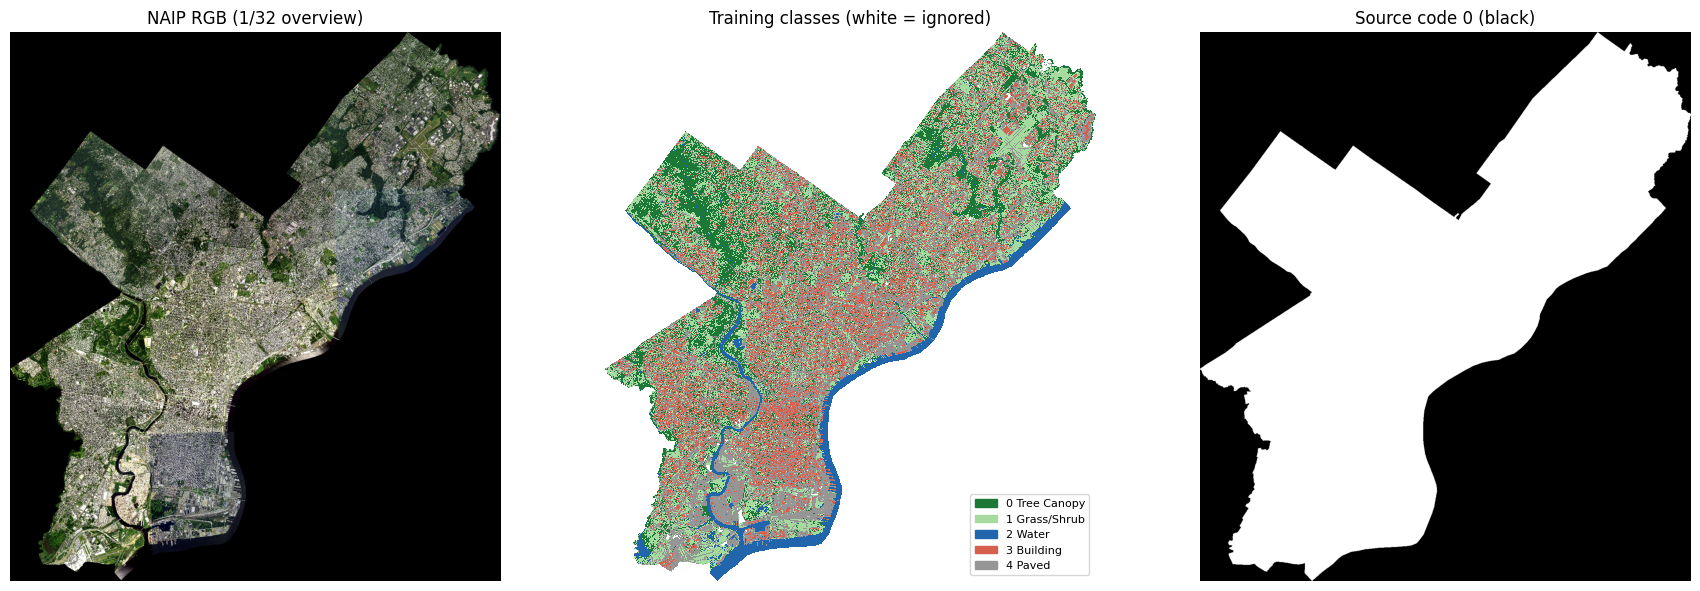

In [4]:
with rasterio.open(LANDCOVER_FILE) as lc, rasterio.open(NAIP_FILE) as naip:
    grids = pd.DataFrame({
        "land cover": [lc.crs.to_string(), lc.count, lc.dtypes[0], f"{lc.res[0]:.3f} x {lc.res[1]:.3f}",
                       f"{lc.width} x {lc.height}", lc.nodata, tuple(round(v) for v in lc.bounds)],
        "NAIP": [naip.crs.to_string(), naip.count, naip.dtypes[0], f"{naip.res[0]:.3f} x {naip.res[1]:.3f}",
                 f"{naip.width} x {naip.height}", naip.nodata, tuple(round(v) for v in naip.bounds)],
    }, index=["CRS", "bands", "dtype", "pixel size (ft)", "width x height", "declared nodata", "bounds (ft)"])
    display(grids)
    print("Same CRS:", lc.crs == naip.crs)

    # Count raw codes over the whole raster in row strips (the raster is ~2.2 billion pixels).
    counts = np.zeros(256, dtype=np.int64)
    for r0 in range(0, lc.height, 2048):
        win = Window(0, r0, lc.width, min(2048, lc.height - r0))
        counts += np.bincount(lc.read(1, window=win).ravel(), minlength=256)

    # 1/32 overview of both rasters on the land cover grid, for the NDVI check and a quick map.
    F = 32
    ch, cw = lc.height // F, lc.width // F
    lc_small = lc.read(1, window=Window(0, 0, cw * F, ch * F), out_shape=(ch, cw), resampling=Resampling.nearest)
    with WarpedVRT(naip, crs=lc.crs, transform=lc.transform * Affine.scale(F), width=cw, height=ch,
                   resampling=Resampling.nearest) as vrt:
        naip_small = vrt.read(IN_BANDS)

total = counts.sum()
valid_total = sum(counts[c] for c in SOURCE_TO_CLASS)
if lc.nodata is not None:
    print(f"Pixels with the declared nodata value {lc.nodata:.0f}: {counts[int(lc.nodata)]:,}")

red, nir = naip_small[RED_I].astype(float), naip_small[NIR_I].astype(float)
ndvi = (nir - red) / np.maximum(nir + red, 1)
has_img = naip_small.max(axis=0) > 0

rows = []
for c in np.nonzero(counts)[0]:
    class_id = SOURCE_TO_CLASS.get(int(c))
    sel = (lc_small == c) & has_img
    rows.append({
        "source code": int(c),
        "source class": SOURCE_LEGEND.get(int(c), "UNDOCUMENTED"),
        "pixels": int(counts[c]),
        "% of raster": 100 * counts[c] / total,
        "% of valid": 100 * counts[c] / valid_total if class_id is not None else np.nan,
        "mean NDVI": ndvi[sel].mean() if sel.any() else np.nan,
        "training ID": class_id if class_id is not None else IGNORE_INDEX,
        "training class": CLASS_NAMES[class_id] if class_id is not None else "ignored",
    })
code_table = pd.DataFrame(rows)
display(code_table.style.format({"pixels": "{:,}", "% of raster": "{:.2f}", "% of valid": "{:.2f}", "mean NDVI": "{:.3f}"}))

class_table = (code_table[code_table["training ID"] != IGNORE_INDEX]
               .groupby(["training ID", "training class"], as_index=False)["pixels"].sum())
class_table["% of valid"] = 100 * class_table["pixels"] / class_table["pixels"].sum()
display(class_table.style.format({"pixels": "{:,}", "% of valid": "{:.2f}"}))
code_table.to_csv(OUT_DIR / "source_codes.csv", index=False)
class_table.to_csv(OUT_DIR / "class_mapping_counts.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(stretch(naip_small[RGB_IDX]))
axes[0].set_title("NAIP RGB (1/32 overview)")
axes[0].axis("off")
show_labels(axes[1], LUT[lc_small], "Training classes (white = ignored)")
axes[1].legend(handles=LEGEND, loc="lower right", fontsize=8)
axes[2].imshow(np.where(lc_small == 0, 1, 0), cmap="gray_r")
axes[2].set_title("Source code 0 (black)")
axes[2].axis("off")
plt.tight_layout()
plt.show()

In [5]:
with rasterio.open(NAIP_FILE) as s:
    print("descriptions:", s.descriptions, "| colorinterp:", s.colorinterp)
    print("tags:", s.tags(), [s.tags(i) for i in range(1, 5)])
for b in range(4):
    means = {SOURCE_LEGEND[c]: round(float(naip_small[b][(lc_small == c) & has_img].mean()), 1) for c in [1, 2, 4, 5, 7]}
    print(f"band {b + 1}:", means)

descriptions: (None, None, None, None) | colorinterp: (<ColorInterp.red: 3>, <ColorInterp.green: 4>, <ColorInterp.blue: 5>, <ColorInterp.alpha: 6>)
tags: {'AREA_OR_POINT': 'Area'} [{}, {}, {}, {}]
band 1: {'Tree Canopy': 180.2, 'Grass/Shrub': 172.0, 'Water': 31.5, 'Building': 132.5, 'Other Paved Surfaces': 138.9}
band 2: {'Tree Canopy': 99.9, 'Grass/Shrub': 124.8, 'Water': 93.4, 'Building': 175.9, 'Other Paved Surfaces': 172.4}
band 3: {'Tree Canopy': 127.5, 'Grass/Shrub': 148.3, 'Water': 110.4, 'Building': 183.6, 'Other Paved Surfaces': 180.8}
band 4: {'Tree Canopy': 103.8, 'Grass/Shrub': 118.8, 'Water': 103.8, 'Building': 173.2, 'Other Paved Surfaces': 162.0}


**What to check above:** code 0 should lie outside the city boundary (right panel), the declared nodata value should have zero pixels, and mean NDVI should be high for Tree Canopy and Grass/Shrub, negative for Water, and near zero for built surfaces. That last pattern also confirms that band 1 is NIR.

**Handling of excluded pixels:** codes 0 and 3 and any pixel without NAIP coverage become `255`. `CrossEntropyLoss(ignore_index=255)` skips them, and every metric below excludes them.

### H5. Build aligned 256 × 256 tiles

- The NAIP image (3.28 ft) is resampled **bilinearly** onto the land cover grid (2 ft) through a `WarpedVRT`, so each image tile and label tile share one CRS, extent, and pixel size. Labels are never resampled.
- Labels are mapped to training IDs with the lookup table, so this is the only label-loading path.
- A tile is kept when at least 30% of its pixels are labelled. Partial edge tiles are padded with ignored pixels.
- Tiles are stored as two `.npy` arrays. This cell is skipped when `tiles.csv` already exists; delete `TILE_DIR` after changing the tiling settings.

In [6]:
IMG_NPY, MSK_NPY, META_CSV = TILE_DIR / "images_uint8.npy", TILE_DIR / "masks_uint8.npy", TILE_DIR / "tiles.csv"

if META_CSV.exists():
    tiles = pd.read_csv(META_CSV)
    print(f"Loaded {len(tiles):,} existing tiles from {TILE_DIR}")
else:
    t0 = time.time()
    with rasterio.open(LANDCOVER_FILE) as lc, rasterio.open(NAIP_FILE) as naip:
        n_rows, n_cols = math.ceil(lc.height / TILE), math.ceil(lc.width / TILE)

        def label_strip(i):
            h = min(TILE, lc.height - i * TILE)
            win = Window(0, i * TILE, lc.width, h)
            return win, LUT[lc.read(1, window=win)]

        def pad_tile(strip, j, fill):
            """Cut tile column j out of a strip and pad partial edge tiles to TILE x TILE."""
            w = min(TILE, strip.shape[-1] - j * TILE)
            out = np.full(strip.shape[:-2] + (TILE, TILE), fill, dtype=np.uint8)
            out[..., :strip.shape[-2], :w] = strip[..., j * TILE:j * TILE + w]
            return out

        # Pass 1 (labels only): which tiles can reach the valid-pixel threshold?
        candidates = {}
        for i in range(n_rows):
            _, lab = label_strip(i)
            cols = [j for j in range(n_cols)
                    if (pad_tile(lab, j, IGNORE_INDEX) != IGNORE_INDEX).mean() >= MIN_VALID_FRAC]
            if cols:
                candidates[i] = cols
        capacity = sum(len(v) for v in candidates.values())
        print(f"Tile grid {n_rows} x {n_cols}; {capacity:,} candidate tiles ({time.time() - t0:.0f}s)")

        # Pass 2: read NAIP on the label grid, drop pixels without imagery, write the tiles.
        imgs = np.lib.format.open_memmap(IMG_NPY, mode="w+", dtype=np.uint8, shape=(capacity, len(IN_BANDS), TILE, TILE))
        msks = np.lib.format.open_memmap(MSK_NPY, mode="w+", dtype=np.uint8, shape=(capacity, TILE, TILE))
        records = []
        with WarpedVRT(naip, crs=lc.crs, transform=lc.transform, width=lc.width, height=lc.height,
                       resampling=Resampling.bilinear) as vrt:
            for k, (i, cols) in enumerate(candidates.items()):
                win, lab = label_strip(i)
                img = vrt.read(IN_BANDS, window=win)
                lab[img.max(axis=0) == 0] = IGNORE_INDEX
                for j in cols:
                    m = pad_tile(lab, j, IGNORE_INDEX)
                    valid_frac = (m != IGNORE_INDEX).mean()
                    if valid_frac < MIN_VALID_FRAC:
                        continue
                    n = len(records)
                    imgs[n] = pad_tile(img, j, 0)
                    msks[n] = m
                    px = np.bincount(m[m != IGNORE_INDEX], minlength=NUM_CLASSES)
                    records.append({"idx": n, "row": i, "col": j, "valid_frac": valid_frac,
                                    **{f"px_{c}": int(px[c]) for c in range(NUM_CLASSES)}})
                if k % 20 == 0:
                    print(f"  strip {k + 1}/{len(candidates)}: {len(records):,} tiles ({time.time() - t0:.0f}s)")
        imgs.flush()
        msks.flush()
        del imgs, msks
    tiles = pd.DataFrame(records)
    tiles.to_csv(META_CSV, index=False)
    print(f"Wrote {len(tiles):,} tiles in {time.time() - t0:.0f}s")

PX_COLS = [f"px_{c}" for c in range(NUM_CLASSES)]

# Why partial tiles are kept: compare with the tutorial rule (drop a tile if any pixel is invalid).
full = tiles["valid_frac"] >= 1.0
water = tiles[f"px_{CLASS_NAMES.index('Water')}"]
display(pd.DataFrame({
    "tiles": [len(tiles), int(full.sum())],
    "water pixels": [int(water.sum()), int(water[full].sum())],
    "all labelled pixels": [int(tiles[PX_COLS].values.sum()), int(tiles.loc[full, PX_COLS].values.sum())],
}, index=[f"keep >= {MIN_VALID_FRAC:.0%} valid (used)", "keep only fully valid tiles"]).style.format("{:,}"))

Loaded 15,257 existing tiles from /content/data/lab9_hw_multiclass/tiles


,tiles,water pixels,all labelled pixels
keep >= 30% valid (used),"15,257","54,635,151","984,869,917"
keep only fully valid tiles,"13,501","43,825,165","884,801,536"


### H6. Step 2 — Spatial split

Tiles are grouped into 8 × 8-tile blocks (≈ 4,096 ft ≈ 1.25 km). Blocks are shuffled with a fixed seed and assigned to test, validation, and training until each reaches its share of tiles. A 1-tile **buffer** then removes any tile whose 8-neighbourhood touches a higher-priority split (test > validation > training), so no two adjacent tiles end up in different splits. Splitting happens before augmentation. If a split were missing a class, the next seed is tried; the seed used is printed and saved.

Split seed: 42


,tiles,% of tiles,% Tree Canopy,% Grass/Shrub,% Water,% Building,% Paved
split,,,,,,,
train,9188,60.2,18.0,23.1,4.7,18.9,35.3
val,2132,14.0,21.3,22.8,9.7,14.4,31.7
test,2241,14.7,17.6,25.8,4.7,16.3,35.6
buffer,1696,11.1,19.9,23.3,6.0,16.8,34.1


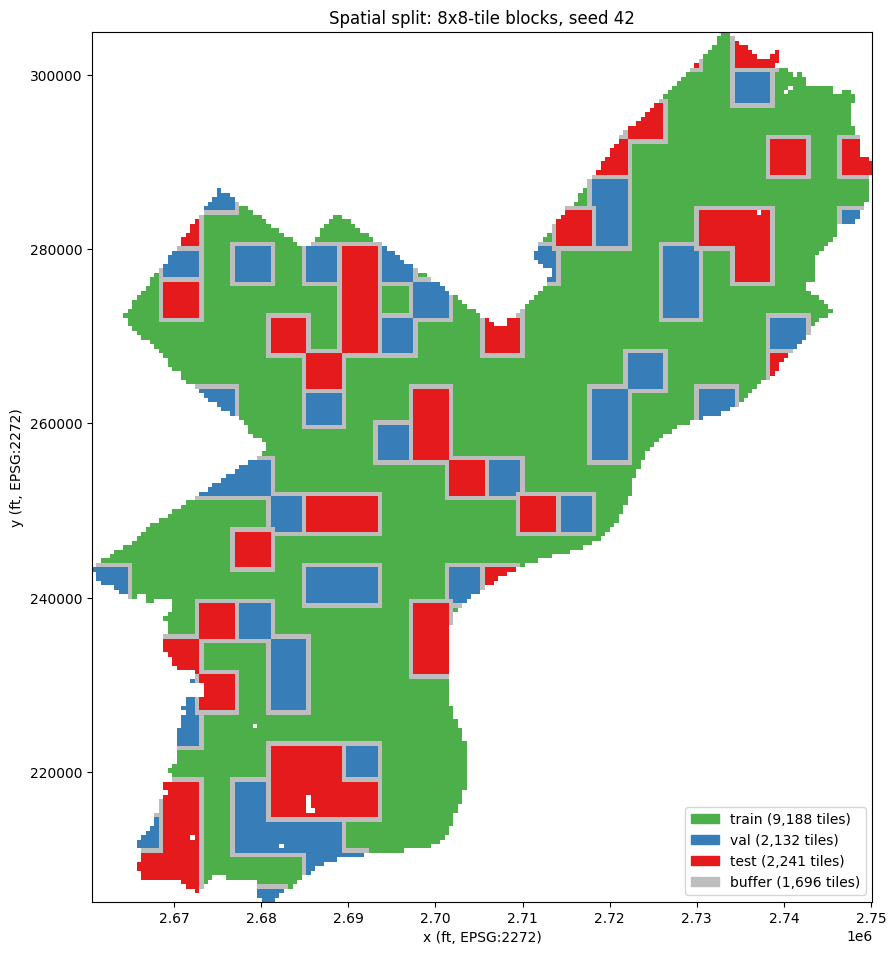

In [7]:
PRIORITY = {"train": 1, "val": 2, "test": 3}
tiles["block"] = (tiles["row"] // BLOCK) * 100_000 + (tiles["col"] // BLOCK)
grid_rows, grid_cols = tiles["row"].max() + 1, tiles["col"].max() + 1


def make_split(seed):
    rng = np.random.default_rng(seed)
    sizes = tiles.groupby("block").size()
    order = rng.permutation(sizes.index.to_numpy())
    cum = np.cumsum(sizes.loc[order].to_numpy()) / sizes.sum()
    names = np.where(cum <= SPLIT_FRAC["test"], "test",
                     np.where(cum <= SPLIT_FRAC["test"] + SPLIT_FRAC["val"], "val", "train"))
    split = tiles["block"].map(dict(zip(order, names)))

    # Buffer: drop a tile if any neighbour belongs to a higher-priority split.
    grid = np.zeros((grid_rows, grid_cols), dtype=np.int8)
    grid[tiles["row"], tiles["col"]] = split.map(PRIORITY).to_numpy()
    neighbour_max = ndimage.maximum_filter(grid, size=3, mode="constant", cval=0)
    buffered = neighbour_max[tiles["row"], tiles["col"]] > grid[tiles["row"], tiles["col"]]
    return split.where(~buffered, "buffer")


for SPLIT_SEED in range(SEED, SEED + 50):
    tiles["split"] = make_split(SPLIT_SEED)
    per_split = tiles[tiles["split"] != "buffer"].groupby("split")[PX_COLS].sum()
    if len(per_split) == 3 and (per_split > 0).all().all():
        break
else:
    raise RuntimeError("No seed gave every split all classes; adjust BLOCK or SPLIT_FRAC.")
print(f"Split seed: {SPLIT_SEED}")

summary = tiles.groupby("split").size().rename("tiles").to_frame()
summary["% of tiles"] = 100 * summary["tiles"] / len(tiles)
px = tiles.groupby("split")[PX_COLS].sum()
for c, name in enumerate(CLASS_NAMES):
    summary[f"% {name}"] = 100 * px[f"px_{c}"] / px.sum(axis=1)
summary = summary.reindex(["train", "val", "test", "buffer"]).fillna(0)
display(summary.style.format({"% of tiles": "{:.1f}", **{f"% {n}": "{:.1f}" for n in CLASS_NAMES}}))
tiles.to_csv(OUT_DIR / "tiles_split.csv", index=False)

train_idx = tiles.loc[tiles["split"] == "train", "idx"].to_numpy()
val_idx = tiles.loc[tiles["split"] == "val", "idx"].to_numpy()
test_idx = tiles.loc[tiles["split"] == "test", "idx"].to_numpy()

# Map of the split on the tile grid, in State Plane feet.
with rasterio.open(LANDCOVER_FILE) as lc:
    x0, y0 = lc.transform * (0, 0)
    tile_ft = TILE * lc.res[0]
extent = [x0, x0 + grid_cols * tile_ft, y0 - grid_rows * tile_ft, y0]
split_colors = {"train": "#4daf4a", "val": "#377eb8", "test": "#e41a1c", "buffer": "#bdbdbd"}
grid = np.full((grid_rows, grid_cols), np.nan)
for k, name in enumerate(split_colors):
    sel = tiles["split"] == name
    grid[tiles.loc[sel, "row"], tiles.loc[sel, "col"]] = k
fig, ax = plt.subplots(figsize=(9, 10))
ax.imshow(np.ma.masked_invalid(grid), cmap=ListedColormap(list(split_colors.values())),
          norm=BoundaryNorm(np.arange(-0.5, 4.5), 4), extent=extent, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=f"{n} ({(tiles['split'] == n).sum():,} tiles)") for n, c in split_colors.items()],
          loc="lower right")
ax.set_title(f"Spatial split: {BLOCK}x{BLOCK}-tile blocks, seed {SPLIT_SEED}")
ax.set_xlabel("x (ft, EPSG:2272)")
ax.set_ylabel("y (ft, EPSG:2272)")
plt.tight_layout()
plt.savefig(OUT_DIR / "spatial_split_map.png", dpi=150)
plt.show()

### H7. Dataset and data loaders

- Inputs: the 4 NAIP bands scaled to [0, 1], then standardized with per-band mean and std from a sample of **training** tiles.
- Labels are already training IDs (`long`, 255 = ignore), with shape `[N, H, W]`.
- Augmentation (training only): one random 90° rotation and horizontal flip, sampled once and applied to the image and the mask together. No colour changes.

In [8]:
_rng = np.random.default_rng(SEED)
_sample_idx = np.sort(_rng.choice(train_idx, size=min(400, len(train_idx)), replace=False))
_sample = np.load(IMG_NPY, mmap_mode="r")[_sample_idx].astype(np.float32) / 255.0
_has_img = _sample.max(axis=1) > 0
BAND_MEAN = np.array([_sample[:, b][_has_img].mean() for b in range(len(IN_BANDS))], dtype=np.float32)
BAND_STD = np.array([_sample[:, b][_has_img].std() for b in range(len(IN_BANDS))], dtype=np.float32)
del _sample
print("Band mean:", BAND_MEAN.round(4))
print("Band std: ", BAND_STD.round(4))


class LandCoverTiles(Dataset):
    def __init__(self, indices, augment=False):
        self.indices = np.asarray(indices)
        self.augment = augment
        self.mean = torch.from_numpy(BAND_MEAN).view(-1, 1, 1)
        self.std = torch.from_numpy(BAND_STD).view(-1, 1, 1)
        self.imgs = self.msks = None  # opened lazily so each worker gets its own memmap

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        if self.imgs is None:
            self.imgs = np.load(IMG_NPY, mmap_mode="r")
            self.msks = np.load(MSK_NPY, mmap_mode="r")
        k = self.indices[i]
        x = (torch.from_numpy(self.imgs[k].astype(np.float32) / 255.0) - self.mean) / self.std
        y = torch.from_numpy(self.msks[k].astype(np.int64))
        if self.augment:
            r = int(torch.randint(4, (1,)))
            x, y = torch.rot90(x, r, dims=(1, 2)), torch.rot90(y, r, dims=(0, 1))
            if torch.rand(1).item() < 0.5:
                x, y = torch.flip(x, dims=(2,)), torch.flip(y, dims=(1,))
        return x.contiguous(), y.contiguous()


def make_loader(indices, augment=False, shuffle=False, seed=SEED):
    kwargs = dict(batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                  pin_memory=DEVICE.type == "cuda", generator=torch.Generator().manual_seed(seed))
    if NUM_WORKERS > 0 and shuffle:
        kwargs["persistent_workers"] = True  # reused every epoch
    return DataLoader(LandCoverTiles(indices, augment), **kwargs)


val_dl = make_loader(val_idx)
test_dl = make_loader(test_idx)

xb, yb = next(iter(make_loader(train_idx, augment=True, shuffle=True)))
print("image batch:", tuple(xb.shape), xb.dtype, "| label batch:", tuple(yb.shape), yb.dtype)
print("label values in batch:", torch.unique(yb).tolist())

Band mean: [0.579  0.562  0.6247 0.5467]
Band std:  [0.2227 0.2102 0.1772 0.1799]
image batch: (16, 4, 256, 256) torch.float32 | label batch: (16, 256, 256) torch.int64
label values in batch: [0, 1, 2, 3, 4, 255]


### H8. U-Net with 4 input bands and C = 5 outputs

Same architecture as the tutorial; only `in_channels` (4) and `out_channels` (5) change. The output stays as raw logits for `CrossEntropyLoss`.

In [9]:
class UNET(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = self.contract_block(in_channels, 32, 7, 3)
        self.conv2 = self.contract_block(32, 64, 3, 1)
        self.conv3 = self.contract_block(64, 128, 3, 1)
        self.upconv3 = self.expand_block(128, 64, 3, 1)
        self.upconv2 = self.expand_block(64 * 2, 32, 3, 1)
        self.upconv1 = self.expand_block(32 * 2, out_channels, 3, 1)

    def forward(self, x):
        conv1 = self.conv1(x)
        conv2 = self.conv2(conv1)
        conv3 = self.conv3(conv2)
        upconv3 = self.upconv3(conv3)
        upconv2 = self.upconv2(torch.cat([upconv3, conv2], 1))
        return self.upconv1(torch.cat([upconv2, conv1], 1))

    def contract_block(self, in_channels, out_channels, kernel_size, padding):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

    def expand_block(self, in_channels, out_channels, kernel_size, padding):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size, stride=1, padding=padding),
            nn.BatchNorm2d(out_channels), nn.ReLU(),
            nn.ConvTranspose2d(out_channels, out_channels, kernel_size=3, stride=2, padding=1, output_padding=1),
        )


_m = UNET(len(IN_BANDS), NUM_CLASSES)
print(f"Parameters: {sum(p.numel() for p in _m.parameters()):,}")
print("Output shape for one tile:", tuple(_m(torch.zeros(1, len(IN_BANDS), TILE, TILE)).shape))
del _m

Parameters: 541,061
Output shape for one tile: (1, 5, 256, 256)


### H9. Training loop and metrics

- Metrics come from a confusion matrix over **valid pixels only** (`255` excluded). Rows are reference classes, columns are predictions.
- `IoU = TP / (TP + FP + FN)`. A class absent from both reference and prediction gets IoU = NaN and is left out of mIoU (`nanmean`).
- Batches with no valid pixels are skipped, so the loss is never undefined.
- Each epoch is followed by validation in `eval()` mode under `no_grad`. The checkpoint with the best **validation mIoU** is saved. The learning rate halves after 3 epochs without improvement, and training stops after `PATIENCE` epochs without improvement.
- Mixed precision (float16) is used on GPU for speed.

In [10]:
RUN_CONFIG = {
    "seed": SEED, "split_seed": int(SPLIT_SEED), "classes": CLASS_NAMES,
    "source_to_class": {str(k): v for k, v in SOURCE_TO_CLASS.items()},
    "ignored_source_codes": [0, 3], "ignore_index": IGNORE_INDEX,
    "input_bands": IN_BANDS,
    "normalization": {"scale": "1/255", "mean": BAND_MEAN.tolist(), "std": BAND_STD.tolist()},
    "tile": TILE, "min_valid_frac": MIN_VALID_FRAC, "block_tiles": BLOCK, "split_frac": SPLIT_FRAC,
    "tiles": {s: int((tiles["split"] == s).sum()) for s in ["train", "val", "test", "buffer"]},
    "augmentation": "random rot90 + horizontal flip (train only, shared image/mask)",
    "optimizer": "Adam", "lr": LR, "lr_schedule": "ReduceLROnPlateau(max val mIoU, factor 0.5, patience 3)",
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "early_stopping_patience": PATIENCE,
    "amp": USE_AMP,
}
(OUT_DIR / "run_config.json").write_text(json.dumps(RUN_CONFIG, indent=2))


def update_cm(cm, pred, y):
    valid = y != IGNORE_INDEX
    cm += torch.bincount(y[valid] * NUM_CLASSES + pred[valid], minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)


def metrics_from_cm(cm):
    cm = cm.astype(np.float64)
    tp, ref, pred = np.diag(cm), cm.sum(axis=1), cm.sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(ref + pred - tp > 0, tp / (ref + pred - tp), np.nan)
        precision = np.where(pred > 0, tp / pred, np.nan)
        recall = np.where(ref > 0, tp / ref, np.nan)
    return {"cm": cm, "pixel_acc": tp.sum() / cm.sum(), "iou": iou, "miou": np.nanmean(iou),
            "precision": precision, "recall": recall}


def run_epoch(model, loader, loss_fn, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=DEVICE)
    loss_sum, n_valid = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        nv = int((y != IGNORE_INDEX).sum())
        if nv == 0:
            continue
        with torch.set_grad_enabled(training), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = loss_fn(logits, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        loss_sum += loss.item() * nv
        n_valid += nv
        update_cm(cm, logits.argmax(dim=1), y)
    return loss_sum / max(n_valid, 1), metrics_from_cm(cm.cpu().numpy())


def fit(run_name, class_weights=None):
    seed_everything(SEED)
    model = UNET(len(IN_BANDS), NUM_CLASSES).to(DEVICE)
    weight = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weight, ignore_index=IGNORE_INDEX)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    train_dl = make_loader(train_idx, augment=True, shuffle=True)
    ckpt_path = OUT_DIR / f"unet_{run_name}_best.pth"

    history, best_miou, wait, t_start = [], -1.0, 0, time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_dl, loss_fn, optimizer, scaler)
        va_loss, va_m = run_epoch(model, val_dl, loss_fn)
        scheduler.step(va_m["miou"])
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                        "train_miou": tr_m["miou"], "val_miou": va_m["miou"], "val_acc": va_m["pixel_acc"],
                        "lr": optimizer.param_groups[0]["lr"]})
        improved = va_m["miou"] > best_miou
        print(f"[{run_name}] epoch {epoch:02d} | train loss {tr_loss:.4f} mIoU {tr_m['miou']:.3f} | "
              f"val loss {va_loss:.4f} mIoU {va_m['miou']:.3f} acc {va_m['pixel_acc']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{'  *best*' if improved else ''}")
        if improved:
            best_miou, wait = va_m["miou"], 0
            torch.save({"state_dict": model.state_dict(), "epoch": epoch, "val_miou": float(best_miou),
                        "run": run_name, "class_weights": class_weights, "config": RUN_CONFIG}, ckpt_path)
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{run_name}] early stop: no val mIoU gain for {PATIENCE} epochs")
                break

    history = pd.DataFrame(history)
    history.to_csv(OUT_DIR / f"history_{run_name}.csv", index=False)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"[{run_name}] best epoch {int(best['epoch'])}: val mIoU {best['val_miou']:.3f} | "
          f"total {(time.time() - t_start) / 60:.1f} min | saved {ckpt_path.name}")
    return history, ckpt_path


def plot_history(history, title):
    best = int(history.loc[history["val_miou"].idxmax(), "epoch"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="validation")
    axes[0].set_ylabel("cross-entropy loss")
    axes[1].plot(history["epoch"], history["train_miou"], label="train mIoU")
    axes[1].plot(history["epoch"], history["val_miou"], label="validation mIoU")
    axes[1].plot(history["epoch"], history["val_acc"], "--", label="validation pixel acc.")
    for ax in axes:
        ax.axvline(best, color="gray", ls=":", label=f"best epoch ({best})")
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"curves_{title.split()[0].lower()}.png", dpi=150)
    plt.show()


def load_model(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model = UNET(len(IN_BANDS), NUM_CLASSES).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt


print(json.dumps(RUN_CONFIG, indent=2))

{
  "seed": 42,
  "split_seed": 42,
  "classes": [
    "Tree Canopy",
    "Grass/Shrub",
    "Water",
    "Building",
    "Paved"
  ],
  "source_to_class": {
    "1": 0,
    "2": 1,
    "4": 2,
    "5": 3,
    "6": 4,
    "7": 4
  },
  "ignored_source_codes": [
    0,
    3
  ],
  "ignore_index": 255,
  "input_bands": [
    1,
    2,
    3,
    4
  ],
  "normalization": {
    "scale": "1/255",
    "mean": [
      0.578974723815918,
      0.5620280504226685,
      0.6247068047523499,
      0.5466518998146057
    ],
    "std": [
      0.22271859645843506,
      0.21024015545845032,
      0.17716935276985168,
      0.17988508939743042
    ]
  },
  "tile": 256,
  "min_valid_frac": 0.3,
  "block_tiles": 8,
  "split_frac": {
    "test": 0.15,
    "val": 0.15,
    "train": 0.7
  },
  "tiles": {
    "train": 9188,
    "val": 2132,
    "test": 2241,
    "buffer": 1696
  },
  "augmentation": "random rot90 + horizontal flip (train only, shared image/mask)",
  "optimizer": "Adam",
  "lr": 0.001,
 

### H10. Step 3 — Experiment A: unweighted loss

[unweighted] epoch 01 | train loss 1.0831 mIoU 0.362 | val loss 0.8908 mIoU 0.531 acc 0.680 | lr 1.0e-03 | 36s  *best*
[unweighted] epoch 02 | train loss 0.8236 mIoU 0.556 | val loss 0.8065 mIoU 0.567 acc 0.702 | lr 1.0e-03 | 32s  *best*
[unweighted] epoch 03 | train loss 0.7651 mIoU 0.582 | val loss 0.7562 mIoU 0.594 acc 0.721 | lr 1.0e-03 | 32s  *best*
[unweighted] epoch 04 | train loss 0.7353 mIoU 0.595 | val loss 0.8044 mIoU 0.574 acc 0.709 | lr 1.0e-03 | 32s
[unweighted] epoch 05 | train loss 0.7232 mIoU 0.600 | val loss 0.7237 mIoU 0.602 acc 0.732 | lr 1.0e-03 | 32s  *best*
[unweighted] epoch 08 | train loss 0.6723 mIoU 0.629 | val loss 0.7002 mIoU 0.622 acc 0.744 | lr 1.0e-03 | 32s  *best*
[unweighted] epoch 11 | train loss 0.6452 mIoU 0.646 | val loss 0.6844 mIoU 0.622 acc 0.749 | lr 1.0e-03 | 32s
[unweighted] epoch 12 | train loss 0.6375 mIoU 0.650 | val loss 0.6936 mIoU 0.624 acc 0.748 | lr 1.0e-03 | 32s
[unweighted] epoch 13 | train loss 0.6380 mIoU 0.649 | val loss 0.6734 m

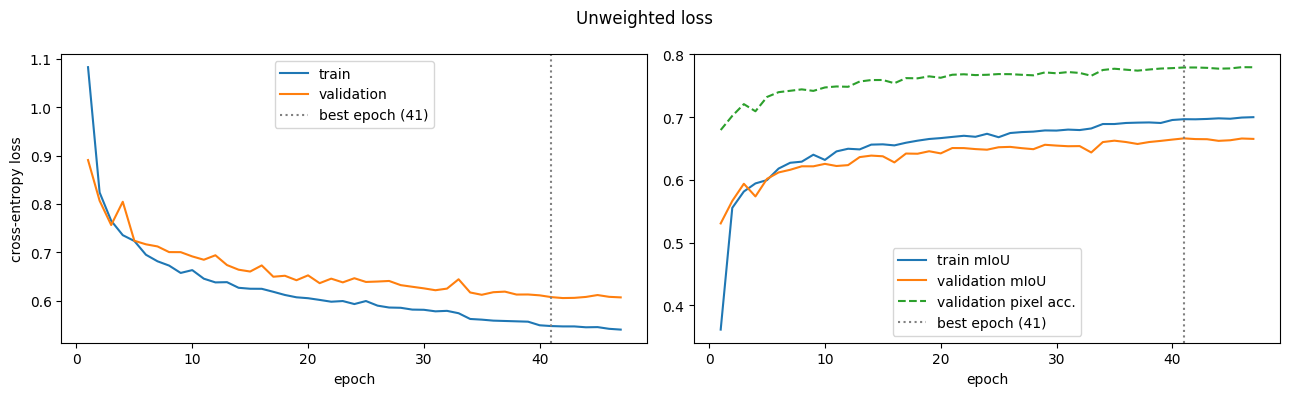

In [11]:
hist_a, ckpt_a = fit("unweighted")
plot_history(hist_a, "Unweighted loss")

### H11. Step 3 — Experiment B: class-weighted loss, then model selection

Weights use median-frequency balancing on **training** pixels: `w_c = median(f) / f_c`, where `f_c` is the share of class c. Rare classes (water) get weights above 1, and common classes (paved) get weights below 1.

Weighted and unweighted losses are on different scales, so the two runs are compared with metrics on the **validation** set. The test set is not used here.

,class,train share %,weight
0,Tree Canopy,18.0,1.05
1,Grass/Shrub,23.1,0.82
2,Water,4.7,4.00
3,Building,18.9,1.00
4,Paved,35.3,0.54


[weighted] epoch 01 | train loss 1.1371 mIoU 0.262 | val loss 0.9577 mIoU 0.313 acc 0.457 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 02 | train loss 0.9222 mIoU 0.426 | val loss 0.8297 mIoU 0.508 acc 0.634 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 03 | train loss 0.8371 mIoU 0.508 | val loss 0.8083 mIoU 0.545 acc 0.668 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 04 | train loss 0.7958 mIoU 0.533 | val loss 0.7766 mIoU 0.562 acc 0.688 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 05 | train loss 0.7673 mIoU 0.548 | val loss 0.7562 mIoU 0.568 acc 0.699 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 06 | train loss 0.7363 mIoU 0.562 | val loss 0.7185 mIoU 0.586 acc 0.711 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 07 | train loss 0.7165 mIoU 0.573 | val loss 0.7530 mIoU 0.570 acc 0.703 | lr 1.0e-03 | 32s
[weighted] epoch 08 | train loss 0.6998 mIoU 0.579 | val loss 0.7109 mIoU 0.592 acc 0.720 | lr 1.0e-03 | 32s  *best*
[weighted] epoch 09 | train loss 0.6788 mIoU 0.587 | val loss 0.6900 mIo

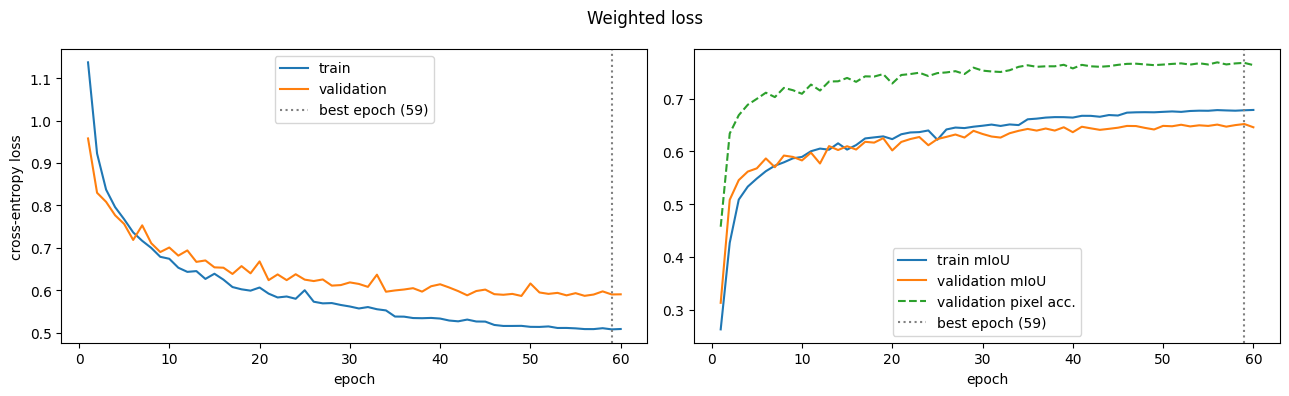

,unweighted,weighted
best epoch,41.000,59.000
val pixel acc,0.779,0.768
val mIoU,0.666,0.652
IoU Tree Canopy,0.626,0.626
IoU Grass/Shrub,0.519,0.505
IoU Water,0.854,0.839
IoU Building,0.652,0.636
IoU Paved,0.680,0.654
recall Tree Canopy,0.745,0.779
recall Grass/Shrub,0.703,0.687


Selected model: unweighted (unet_unweighted_best.pth)


In [12]:
train_px = tiles.loc[tiles["split"] == "train", PX_COLS].sum().to_numpy().astype(float)
freq = train_px / train_px.sum()
CLASS_WEIGHTS = [float(w) for w in np.median(freq) / freq]
display(pd.DataFrame({"class": CLASS_NAMES, "train share %": 100 * freq, "weight": CLASS_WEIGHTS})
        .style.format({"train share %": "{:.1f}", "weight": "{:.2f}"}))

hist_b, ckpt_b = fit("weighted", CLASS_WEIGHTS)
plot_history(hist_b, "Weighted loss")

# Compare both best checkpoints on validation with the same plain loss and metrics.
plain_ce = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
val_results = {}
for name, path in [("unweighted", ckpt_a), ("weighted", ckpt_b)]:
    model, ckpt = load_model(path)
    _, val_results[name] = run_epoch(model, val_dl, plain_ce)
    val_results[name]["epoch"] = ckpt["epoch"]

comparison = pd.DataFrame({
    name: {"best epoch": r["epoch"], "val pixel acc": r["pixel_acc"], "val mIoU": r["miou"],
           **{f"IoU {n}": r["iou"][c] for c, n in enumerate(CLASS_NAMES)},
           **{f"recall {n}": r["recall"][c] for c, n in enumerate(CLASS_NAMES)}}
    for name, r in val_results.items()
})
display(comparison.style.format("{:.3f}"))
comparison.to_csv(OUT_DIR / "validation_comparison.csv")

FINAL_RUN = max(val_results, key=lambda k: val_results[k]["miou"])
FINAL_CKPT = {"unweighted": ckpt_a, "weighted": ckpt_b}[FINAL_RUN]
(OUT_DIR / "final_model.json").write_text(json.dumps(
    {"selected_run": FINAL_RUN, "checkpoint": FINAL_CKPT.name, "criterion": "validation mIoU",
     "val_miou": float(val_results[FINAL_RUN]["miou"])}, indent=2))
print(f"Selected model: {FINAL_RUN} ({FINAL_CKPT.name})")

### H12. Step 4 — Evaluate the selected model on the held-out test area

All choices above are fixed before this cell runs, and the test set is evaluated once.

,IoU,precision,recall,reference pixels,reference share %
Tree Canopy,0.556,0.748,0.685,"25,427,428",17.6
Grass/Shrub,0.575,0.713,0.748,"37,234,147",25.8
Water,0.764,0.932,0.809,"6,768,932",4.7
Building,0.669,0.779,0.826,"23,497,045",16.3
Paved,0.729,0.845,0.842,"51,266,329",35.6


Test mIoU: 0.659   (classes absent from reference and prediction, excluded: none)
Test pixel accuracy: 0.786
Pixel accuracy of always predicting the most common class: 0.356


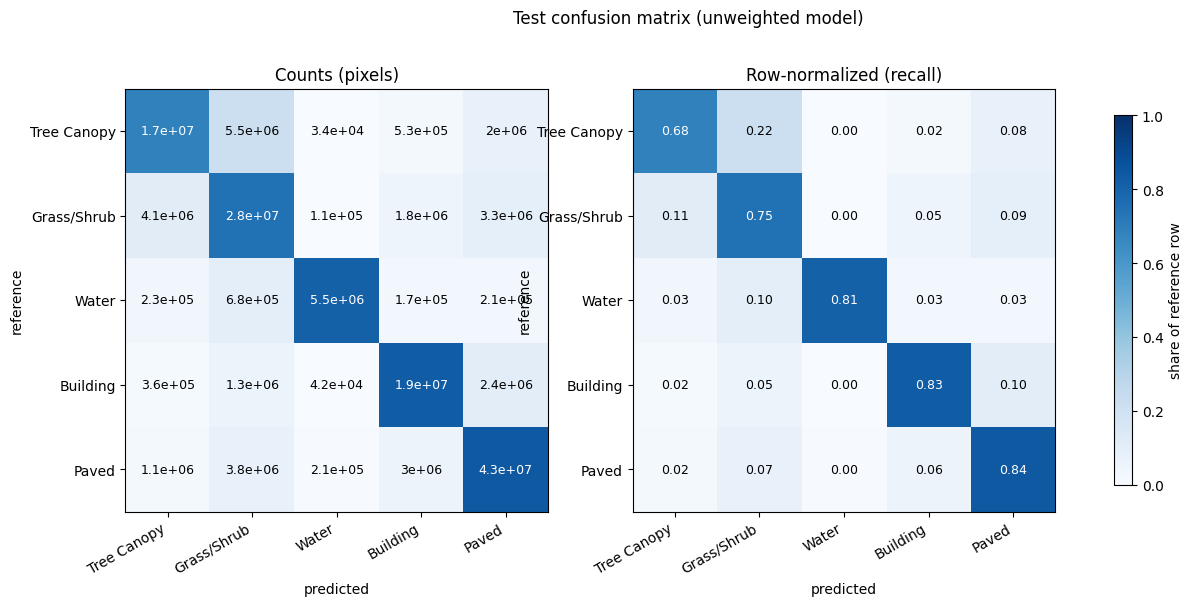

In [13]:
final_model, _ = load_model(FINAL_CKPT)
_, test_m = run_epoch(final_model, test_dl, nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX))
cm = test_m["cm"]

per_class = pd.DataFrame({
    "IoU": test_m["iou"], "precision": test_m["precision"], "recall": test_m["recall"],
    "reference pixels": cm.sum(axis=1).astype(np.int64), "reference share %": 100 * cm.sum(axis=1) / cm.sum(),
}, index=CLASS_NAMES)
display(per_class.style.format({"IoU": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}",
                                "reference pixels": "{:,}", "reference share %": "{:.1f}"}))
per_class.to_csv(OUT_DIR / "test_per_class.csv")

majority = cm.sum(axis=1).max() / cm.sum()
absent = [n for n, v in zip(CLASS_NAMES, test_m["iou"]) if np.isnan(v)]
print(f"Test mIoU: {test_m['miou']:.3f}   (classes absent from reference and prediction, excluded: {absent or 'none'})")
print(f"Test pixel accuracy: {test_m['pixel_acc']:.3f}")
print(f"Pixel accuracy of always predicting the most common class: {majority:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
norm_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
for ax, mat, title, fmt in [(axes[0], cm, "Counts (pixels)", "{:.2g}"),
                            (axes[1], norm_cm, "Row-normalized (recall)", "{:.2f}")]:
    im = ax.imshow(norm_cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                    color="white" if norm_cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("reference")
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8, label="share of reference row")
fig.suptitle(f"Test confusion matrix ({FINAL_RUN} model)")
plt.savefig(OUT_DIR / "test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### H13. Step 4 — Test examples

Four test tiles are drawn (fixed seed) from tiles with at least three classes, so the comparison is not trivial. All label panels use the same colours and legend; white means ignored.

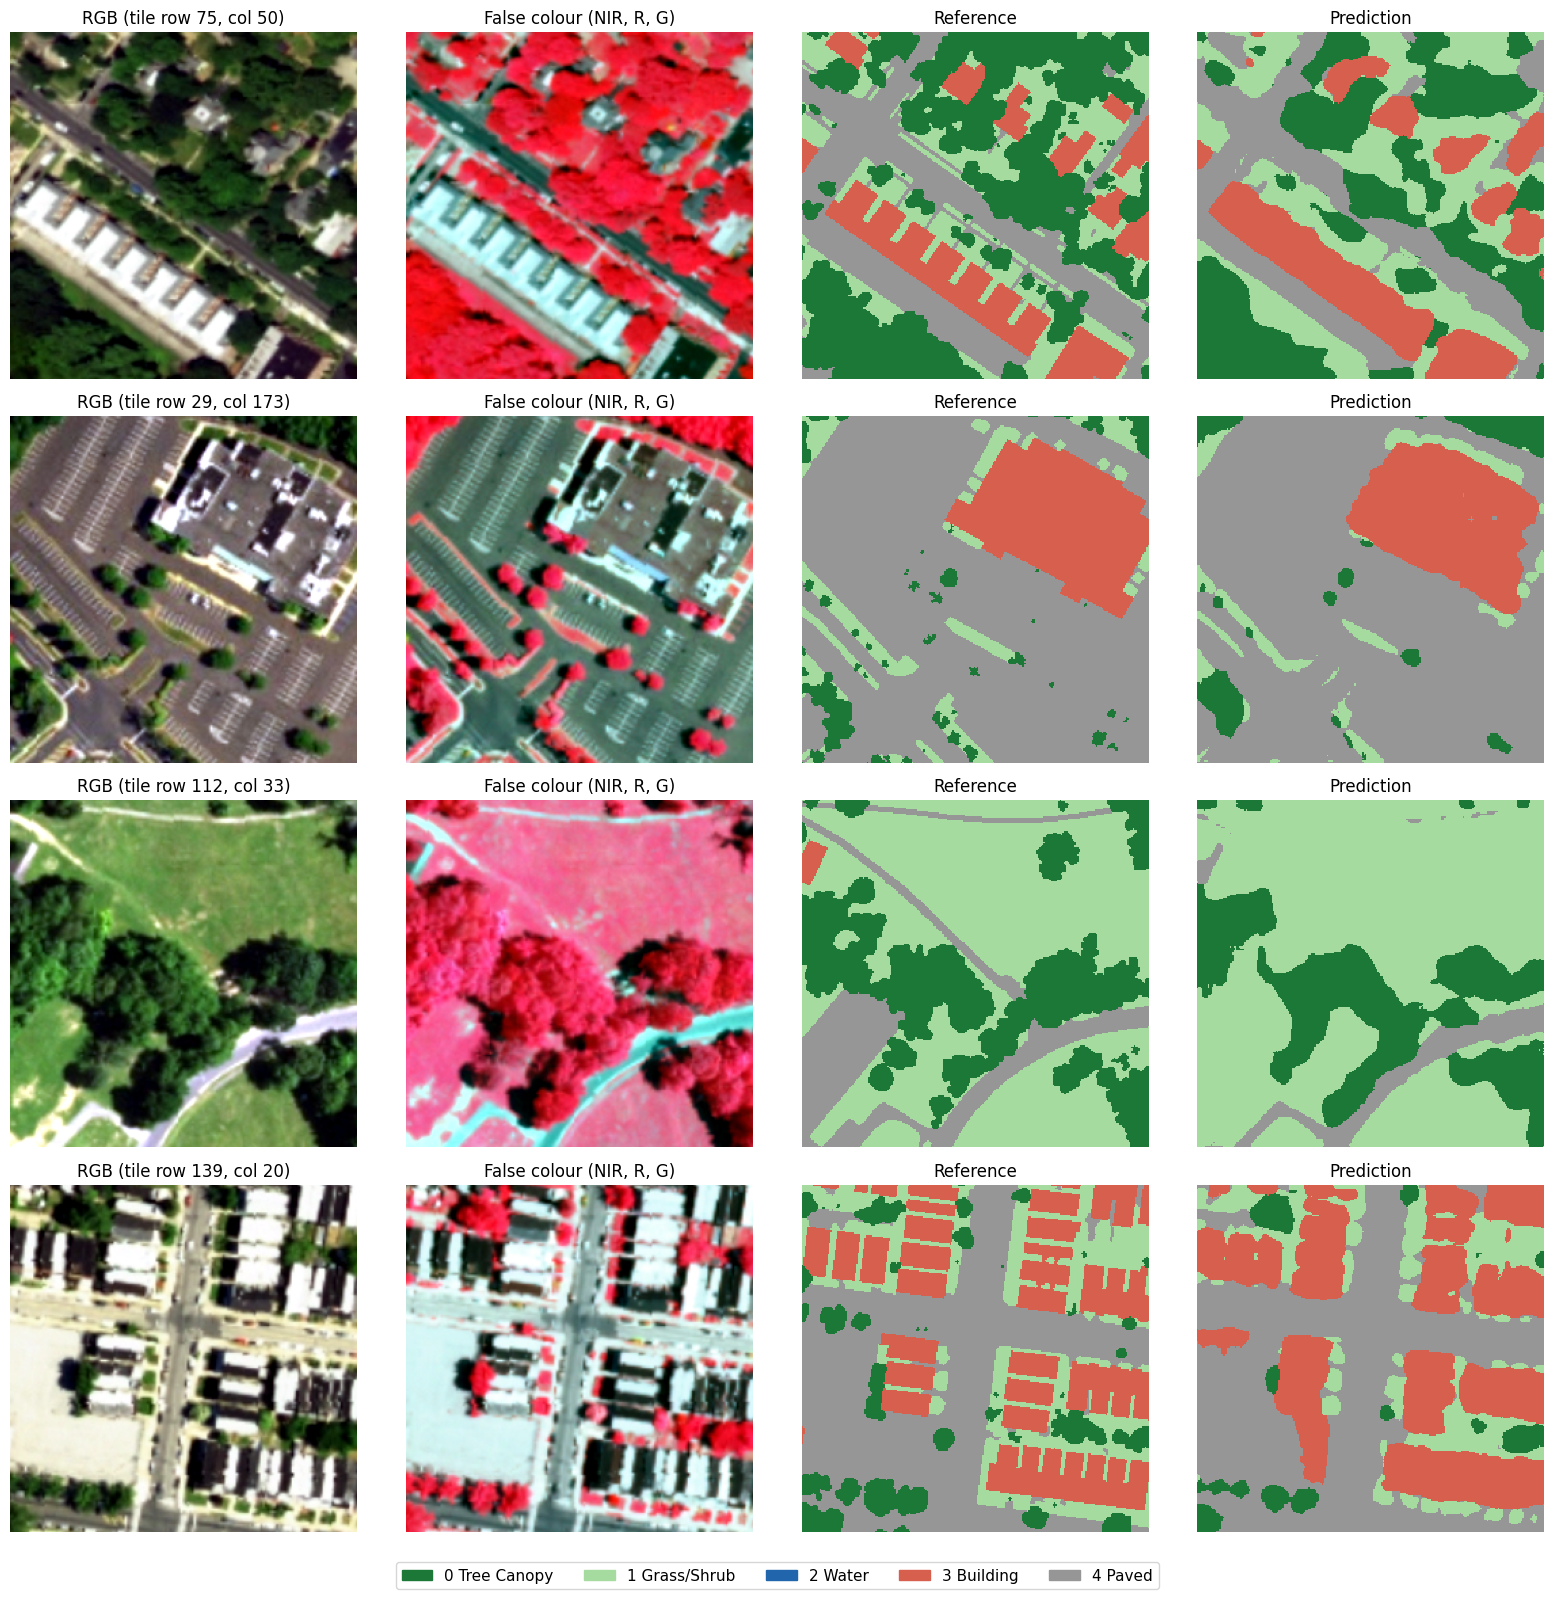

In [14]:
rich = tiles[(tiles["split"] == "test") & ((tiles[PX_COLS] > 0.05 * TILE * TILE).sum(axis=1) >= 3)]
pool = rich if len(rich) >= 4 else tiles[tiles["split"] == "test"]
example_idx = np.random.default_rng(SEED).choice(pool["idx"].to_numpy(), size=4, replace=False)

ds = LandCoverTiles(example_idx)
xb = torch.stack([ds[i][0] for i in range(len(ds))]).to(DEVICE)
with torch.no_grad():
    preds = final_model(xb).argmax(dim=1).cpu().numpy()
raw = np.load(IMG_NPY, mmap_mode="r")

fig, axes = plt.subplots(len(example_idx), 4, figsize=(16, 4 * len(example_idx)))
for r, k in enumerate(example_idx):
    ref = ds[r][1].numpy()
    pred = np.where(ref == IGNORE_INDEX, IGNORE_INDEX, preds[r])
    info = tiles.loc[tiles["idx"] == k].iloc[0]
    axes[r, 0].imshow(stretch(raw[k][RGB_IDX]))
    axes[r, 0].set_title(f"RGB (tile row {int(info['row'])}, col {int(info['col'])})")
    axes[r, 0].axis("off")
    axes[r, 1].imshow(stretch(raw[k][CIR_IDX]))
    axes[r, 1].set_title("False colour (NIR, R, G)")
    axes[r, 1].axis("off")
    show_labels(axes[r, 2], ref, "Reference")
    show_labels(axes[r, 3], pred, "Prediction")
fig.legend(handles=LEGEND, loc="lower center", ncol=NUM_CLASSES, fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(OUT_DIR / "test_examples.png", dpi=150)
plt.show()

### H14. Step 5 — Georeferenced prediction map of the held-out area

- Tiles sit on the land cover grid and do not overlap, so each prediction is written straight into its window with the source transform. No resizing is needed because the model runs at the native 2 ft grid.
- The output covers the bounding box of the test tiles. Pixels outside the test tiles, outside the city (source code 0), or without NAIP data are set to **255 (nodata)**. Bare-soil pixels inside the test area keep the model's prediction, since the model can only output the five classes.
- Values are **training IDs 0–4**; the legend is embedded as a colour table and band tags and is also saved as JSON and PNG.
- Edges: each tile is predicted independently, so faint seams can appear at tile borders, where the network sees less context. Overlapping tiles with averaged logits would reduce this; it is not used here.

Wrote /content/data/lab9_hw_multiclass/outputs/test_area_landcover_prediction.tif (42210 x 48896 px, 8.1 MB)


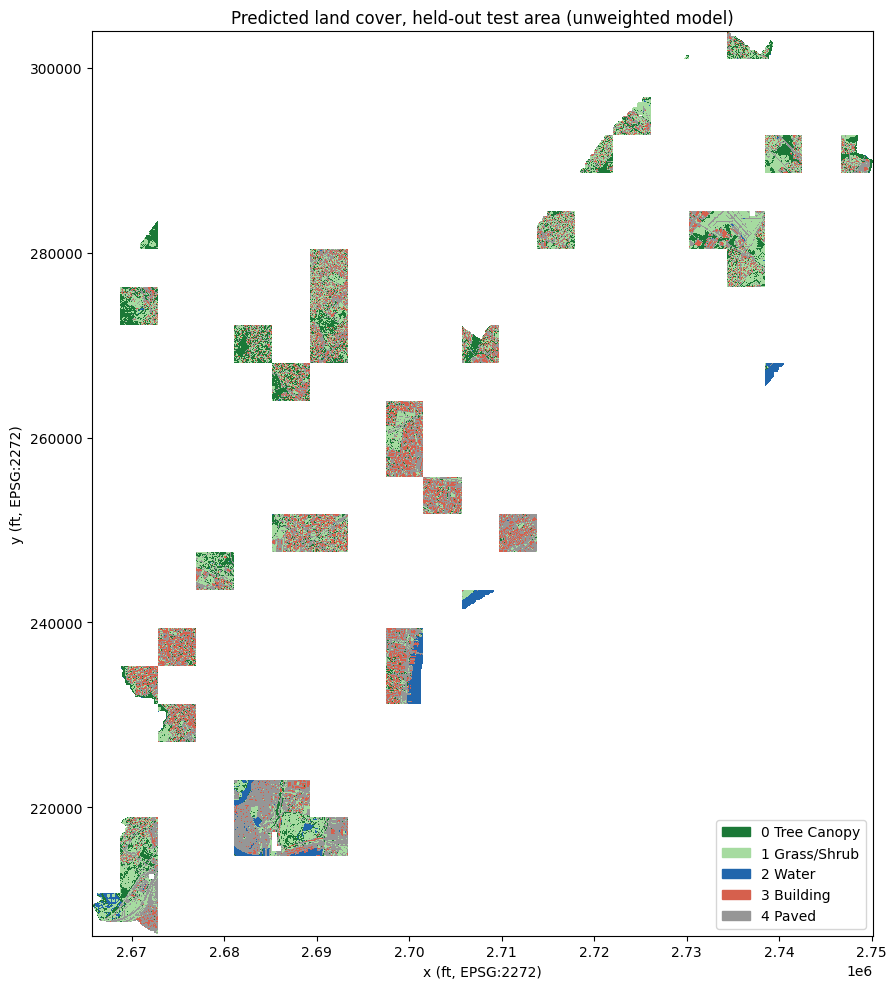

Deliverables in /content/data/lab9_hw_multiclass/outputs
  class_mapping_counts.csv                          0.00 MB
  curves_unweighted.png                             0.10 MB
  curves_weighted.png                               0.11 MB
  final_model.json                                  0.00 MB
  history_unweighted.csv                            0.00 MB
  history_weighted.csv                              0.01 MB
  run_config.json                                   0.00 MB
  source_codes.csv                                  0.00 MB
  spatial_split_map.png                             0.07 MB
  test_area_landcover_legend.json                   0.00 MB
  test_area_landcover_map.png                       0.16 MB
  test_area_landcover_prediction.tif                8.14 MB
  test_confusion_matrix.png                         0.14 MB
  test_examples.png                                 3.44 MB
  test_per_class.csv                                0.00 MB
  tiles_split.csv                          

In [15]:
MAP_NODATA = 255
GEOTIFF = OUT_DIR / "test_area_landcover_prediction.tif"
test_tiles = tiles[tiles["split"] == "test"].reset_index(drop=True)
r0, c0 = test_tiles["row"].min(), test_tiles["col"].min()
r1, c1 = test_tiles["row"].max() + 1, test_tiles["col"].max() + 1

with rasterio.open(LANDCOVER_FILE) as lc:
    out_h = min(r1 * TILE, lc.height) - r0 * TILE
    out_w = min(c1 * TILE, lc.width) - c0 * TILE
    profile = {"driver": "GTiff", "dtype": "uint8", "count": 1, "width": out_w, "height": out_h,
               "crs": lc.crs, "transform": lc.transform * Affine.translation(c0 * TILE, r0 * TILE),
               "nodata": MAP_NODATA, "compress": "deflate", "tiled": True, "blockxsize": 256, "blockysize": 256}

    with rasterio.open(GEOTIFF, "w", **profile) as dst:
        for y in range(0, out_h, 4096):  # start from an all-nodata raster
            h = min(4096, out_h - y)
            dst.write(np.full((1, h, out_w), MAP_NODATA, dtype=np.uint8), window=Window(0, y, out_w, h))

        loader = DataLoader(LandCoverTiles(test_tiles["idx"].to_numpy()), batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=NUM_WORKERS)
        raw = np.load(IMG_NPY, mmap_mode="r")
        k = 0
        with torch.no_grad():
            for x, _ in loader:
                pred = final_model(x.to(DEVICE)).argmax(dim=1).cpu().numpy().astype(np.uint8)
                for p in pred:
                    t = test_tiles.iloc[k]
                    row, col = int(t["row"]), int(t["col"])
                    h = min(TILE, lc.height - row * TILE)
                    w = min(TILE, lc.width - col * TILE)
                    src = lc.read(1, window=Window(col * TILE, row * TILE, w, h))
                    outside = (src == 0) | (raw[int(t["idx"])][:, :h, :w].max(axis=0) == 0)
                    tile_pred = np.where(outside, MAP_NODATA, p[:h, :w]).astype(np.uint8)
                    dst.write(tile_pred[None], window=Window((col - c0) * TILE, (row - r0) * TILE, w, h))
                    k += 1

        colormap = {i: tuple(int(c[j:j + 2], 16) for j in (1, 3, 5)) + (255,) for i, c in enumerate(CLASS_COLORS)}
        colormap[MAP_NODATA] = (0, 0, 0, 0)
        dst.write_colormap(1, colormap)
        dst.set_band_description(1, "land cover class ID (0-4); 255 = nodata")
        dst.update_tags(1, **{f"class_{i}": n for i, n in enumerate(CLASS_NAMES)}, nodata="255")

legend_info = {
    "values": {str(i): {"class": n, "source_codes": [c for c, v in SOURCE_TO_CLASS.items() if v == i], "color": CLASS_COLORS[i]}
               for i, n in enumerate(CLASS_NAMES)},
    "nodata": MAP_NODATA, "crs": "EPSG:2272", "pixel_size_ft": 2.0, "model": FINAL_CKPT.name,
}
(OUT_DIR / "test_area_landcover_legend.json").write_text(json.dumps(legend_info, indent=2))
print(f"Wrote {GEOTIFF} ({out_w} x {out_h} px, {GEOTIFF.stat().st_size / 1e6:.1f} MB)")

# Quick look at the map, read back from the GeoTIFF.
with rasterio.open(GEOTIFF) as src:
    f = max(1, max(src.width, src.height) // 2000)
    quick = src.read(1, out_shape=(src.height // f, src.width // f), resampling=Resampling.nearest)
    b = src.bounds
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(np.ma.masked_equal(quick, MAP_NODATA), cmap=CMAP, norm=NORM, extent=[b.left, b.right, b.bottom, b.top],
          interpolation="nearest")
ax.legend(handles=LEGEND, loc="lower right")
ax.set_title(f"Predicted land cover, held-out test area ({FINAL_RUN} model)")
ax.set_xlabel("x (ft, EPSG:2272)")
ax.set_ylabel("y (ft, EPSG:2272)")
plt.tight_layout()
plt.savefig(OUT_DIR / "test_area_landcover_map.png", dpi=150)
plt.show()

print("Deliverables in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:45s} {p.stat().st_size / 1e6:8.2f} MB")

### H15. Discussion (fill in after running)

- **Class definitions:** five land cover classes from the PASDA legend; Road/Railroad and Other Paved are merged because they look alike from above and differ by use rather than cover. Bare Soil (0.4% of valid pixels) and code 0 are ignored.
- **Spatial split:** see the H6 map and table (tiles per split, class shares, buffer).
- **Weighted vs. unweighted:** see the H11 table. Which classes gained or lost IoU and recall?
- **Pixel accuracy vs. mIoU:** compare test pixel accuracy with the majority-class baseline printed in H12.
- **Main errors:** use the confusion matrix and H13 examples. Look at tree vs. grass, paved vs. building (flat roofs, parking decks), shadows, water vs. dark surfaces, and errors along class boundaries and tile edges.
- **Limitations:** imagery shows land *cover*, not land *use*; the labels (2018 LiDAR + 2017 NAIP) and this NAIP image may come from different dates; tree canopy overhanging roads or roofs is labelled by what is on top; NAIP at ~1 m is upsampled to 2 ft, so fine boundaries are blurred; the test area comes from the same city, so performance elsewhere is unknown.